**2.1 Wrangling dan EDA**

1 & 2. Filtering Timestamp & Export CSV

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv(r'C:\Users\ADVAN\Latihan\.vscode\UTS_GSD\uts-graf\ecommerce-dataset\events.csv')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')


p1_start, p1_end = '2015-06-03', '2015-08-03' # Training (P1)
p2_start, p2_end = '2015-08-12', '2015-08-27' # Testing (P2)

df_p1 = df[(df['datetime'] >= p1_start) & (df['datetime'] <= p1_end)]
df_p2 = df[(df['datetime'] >= p2_start) & (df['datetime'] <= p2_end)]

df_p1.to_csv('events_p1_train.csv', index=False)
df_p2.to_csv('events_p2_test.csv', index=False)

3. Query Komposisi Subgraph dengan Python API & Cypher

In [6]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://localhost:7687", auth=("neo4j", "new12345"))

# Cypher Query untuk menghitung jenis & jumlah simpul
query_nodes = """
MATCH (n) 
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah_simpul
"""

# Cypher Query untuk menghitung jumlah relasi
query_rels = """
MATCH ()-[r]->() 
RETURN type(r) AS jenis_relasi, count(r) AS jumlah_relasi
"""

with driver.session() as session:
    print("--- Komposisi Simpul ---")
    for record in session.run(query_nodes):
        print(f"{record['jenis_simpul']}: {record['jumlah_simpul']}")
        
    print("\n--- Komposisi Relasi ---")
    for record in session.run(query_rels):
        print(f"{record['jenis_relasi']}: {record['jumlah_relasi']}")
driver.close()

--- Komposisi Simpul ---
Visitor: 1407580
Item: 235061

--- Komposisi Relasi ---
VIEWED: 2664312
ADDED_TO_CART: 69332
BOUGHT: 22457


CODE NEO4J :

MATCH (n) RETURN labels(n)[0], count(n)

MATCH ()-[r]->() RETURN type(r), count(r)

4, 5, 6. Vector Space Modelling (VSM) & Proyeksi Bipartite

User Graph: Nodes=724608, Edges=31397015
Item Graph: Nodes=674985, Edges=18053307


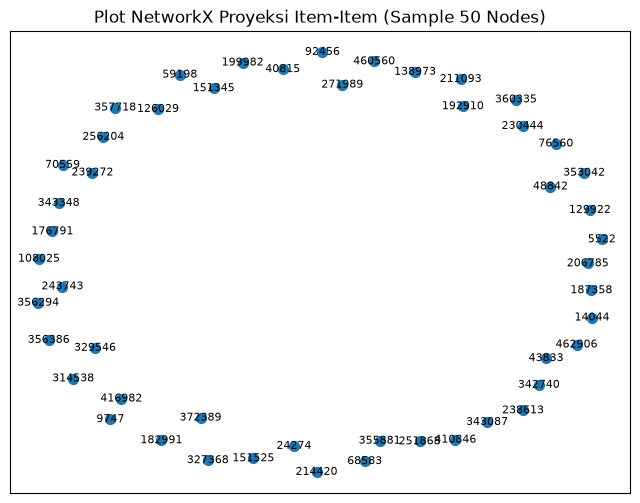

In [7]:
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt

# Buat Bipartite Graph dari dataframe P1
G = nx.Graph()
edges = list(zip(df_p1['visitorid'].astype(str), df_p1['itemid'].astype(str)))
G.add_edges_from(edges)

visitors = set(df_p1['visitorid'].astype(str))
items = set(df_p1['itemid'].astype(str))

# Proyeksi VSM User-User (Visitor Projection)
G_user = bipartite.projected_graph(G, visitors)

# Proyeksi VSM Item-Item (Item Projection)
G_item = bipartite.projected_graph(G, items)

# Karakteristik
print(f"User Graph: Nodes={G_user.number_of_nodes()}, Edges={G_user.number_of_edges()}")
print(f"Item Graph: Nodes={G_item.number_of_nodes()}, Edges={G_item.number_of_edges()}")

# Visualisasi N-sample
plt.figure(figsize=(8,6))
nx.draw_networkx(nx.subgraph(G_item, list(G_item.nodes())[:50]), node_size=50, font_size=8)
plt.title("Plot NetworkX Proyeksi Item-Item (Sample 50 Nodes)")
plt.show()

6. Proyeksi Item-Item umumnya jauh lebih efektif dan efisien dibandingkan User-User. Dalam e-commerce, pola hubungan antar barang (Item Similarity) bersifat lebih stabil dan memiliki dimensi matriks yang lebih kecil dibandingkan interaksi pengguna yang sangat dinamis dan memicu sparsity tinggi.

7. (a) Menghitung Similarity (Cosine / Jaccard) di Python:

In [10]:
import networkx as nx

item_acuan = list(items)[0]

# 1. Ambil kandidat item (item yang memiliki setidaknya 1 pembeli/interaksi yang sama dengan item_acuan)
# Ini menghindari iterasi ke puluhan ribu item yang tidak ada relevansinya sama sekali.
kandidat_items = set()
for user in G.neighbors(item_acuan):  # Tetangga item_acuan di graf Bipartite (Visitor)
    kandidat_items.update(G.neighbors(user))  # Item lain yang diinteraksi oleh Visitor tersebut

kandidat_items.discard(item_acuan)  # Hapus item acuan itu sendiri

# 2. Buat pasangan terbatas hanya untuk (item_acuan, kandidat)
pairs = [(item_acuan, cand) for cand in kandidat_items]

# 3. Hitung Jaccard khusus untuk pasangan tersebut
preds = nx.jaccard_coefficient(G_item, pairs)

# 4. Ambil Top 5 Similarity
top5_sim = sorted(preds, key=lambda x: x[2], reverse=True)[:5]

print("Top 5 Similar Items:", top5_sim)

Top 5 Similar Items: [('329546', '25218', 0.8967851099830795), ('329546', '174533', 0.8967851099830795), ('329546', '64942', 0.8967851099830795), ('329546', '371921', 0.8967851099830795), ('329546', '423743', 0.8967851099830795)]


b.) Tulis Kembali Nilai Similarity ke Dalam Graf Neo4j:

In [ ]:
from neo4j import GraphDatabase

# 1. Pastikan data top5_sim terformat dengan tipe data yang benar
sim_data = []
for u, v, p in top5_sim:
    # Coba konversi ke int jika itemId di Neo4j berupa angka, atau tetapkan str
    try:
        item1_id = int(u)
        item2_id = int(v)
    except ValueError:
        item1_id = str(u)
        item2_id = str(v)
        
    sim_data.append({
        "item1": item1_id,
        "item2": item2_id,
        "score": float(p)
    })

# 2. Query Cypher yang mencakup fallback pencocokan angka/string
query = """
UNWIND $sim_data AS row
MATCH (i1:Item) WHERE i1.itemId = row.item1 OR i1.itemId = toString(row.item1) OR i1.itemId = toInteger(row.item1)
MATCH (i2:Item) WHERE i2.itemId = row.item2 OR i2.itemId = toString(row.item2) OR i2.itemId = toInteger(row.item2)
MERGE (i1)-[r:SIMILAR_TO]->(i2)
SET r.score = row.score
RETURN count(r) AS created_count
"""

NEO4J_PASSWORD = "new12345"  

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", NEO4J_PASSWORD))

with driver.session() as session:
    result = session.run(query, sim_data=sim_data)
    summary = result.single()
    print(f"Jumlah relasi SIMILAR_TO yang berhasil dibuat: {summary['created_count']}")

driver.close()


Jumlah relasi SIMILAR_TO yang berhasil dibuat: 5


CODE NEO4J :

MATCH p=(i1:Item)-[r:SIMILAR_TO]->(i2:Item) 

RETURN p LIMIT 10;

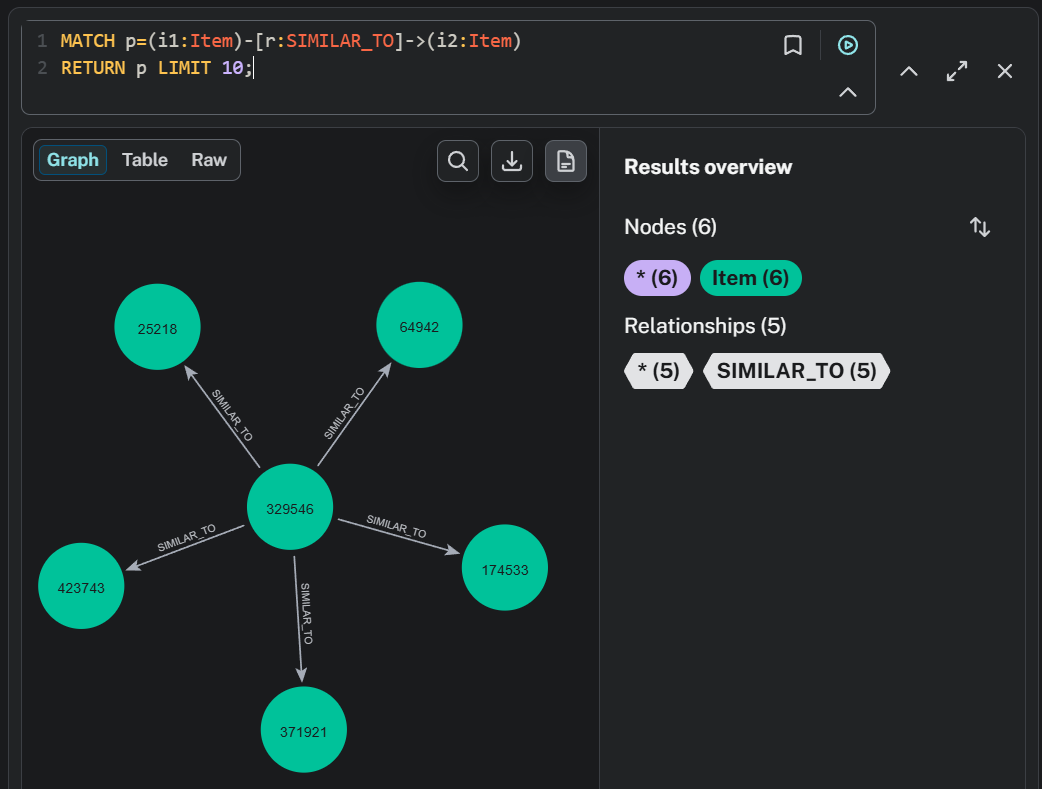

In [ ]:
from IPython.display import Image, display

display(Image(filename="GSD_no.7.png"))

8.Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah 
perhitungan similarity!

sebelum :
MATCH p=(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item) 
RETURN p LIMIT 20;

sesudah :
MATCH p=(i1:Item)-[r:SIMILAR_TO]->(i2:Item) 
RETURN p LIMIT 20;

Sebelum :


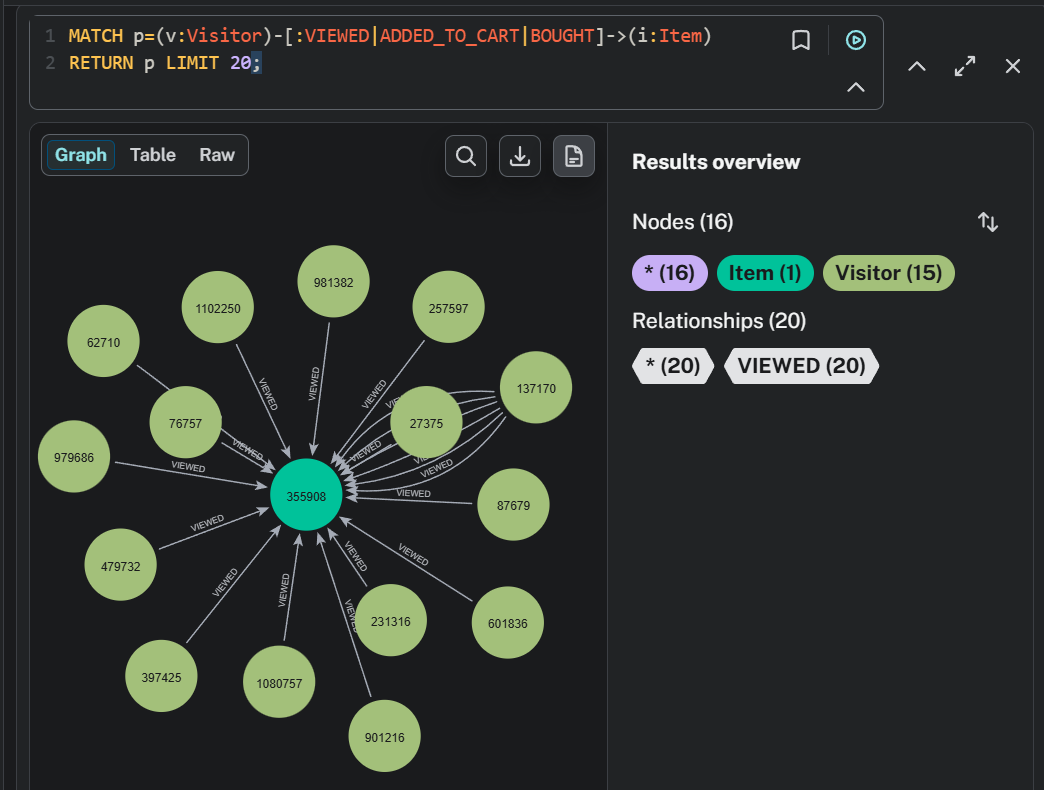

Sesudah :


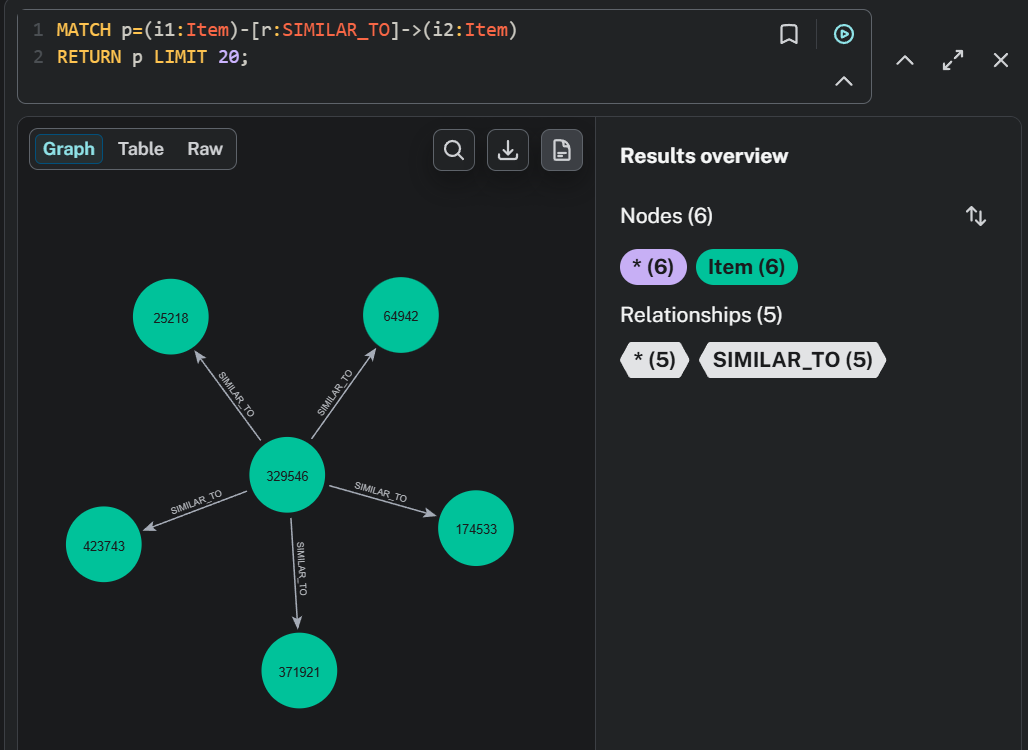

In [31]:
from IPython.display import Image, display

print("Sebelum :")
display(Image(filename="GSD_no.8_sebelum.png"))

print("Sesudah :")
display(Image(filename="GSD_no.8_sesudah.png"))

**2.2 Analytics**

1. Rekomendasi KNN ($k=5$) & Iklan 3 Item

In [18]:
import random
import numpy as np

# Set seed agar hasil reproducible
random.seed(42)
target_user = random.choice(list(visitors))

# Ambil item yang pernah diinteraksi user di P1 (Training)
user_items_train = set(df_p1[df_p1['visitorid'].astype(str) == target_user]['itemid'].astype(str))

# Hitung skor rekomendasi KNN berdasarkan Item Similarity
candidate_scores = {}
for item_train in user_items_train:
    if item_train in G_item:
        for neighbor in G_item.neighbors(item_train):
            if neighbor not in user_items_train:
                candidate_scores[neighbor] = candidate_scores.get(neighbor, 0) + 1

# Urutkan Top-5 rekomendasi KNN
recommended_items = sorted(candidate_scores, key=candidate_scores.get, reverse=True)[:5]
print(f"Top 5 Rekomendasi KNN untuk User {target_user}:", recommended_items)

# (b) 3 Item yang diiklankan dari K=5
sponsored_items = recommended_items[:3]
print("3 Item yang diiklankan:", sponsored_items)

Top 5 Rekomendasi KNN untuk User 281488: ['370408', '294771', '216552', '368130', '735124']
3 Item yang diiklankan: ['370408', '294771', '216552']


2. Evaluasi Metrik (Hit@5 dan NDCG@5)

In [22]:
import numpy as np
import pandas as pd

# 1. Ambil item aktual (ground truth) yang diinteraksi user pada periode testing (P2)
actual_items_test = set(df_p2[df_p2['visitorid'].astype(str) == target_user]['itemid'].astype(str))

# 2. Hitung biner Hit (1 jika item rekomendasi ada di data testing, 0 jika tidak)
hits = [1 if item in actual_items_test else 0 for item in recommended_items]

# (a) Hitung Hit@5
hit_at_5 = 1 if sum(hits) > 0 else 0

# (b) Hitung NDCG@5
def calculate_ndcg(hits_list):
    # Discounted Cumulative Gain (DCG)
    dcg = sum([r / np.log2(idx + 2) for idx, r in enumerate(hits_list)])
    
    # Ideal Discounted Cumulative Gain (IDCG)
    ideal_hits = sorted(hits_list, reverse=True)
    idcg = sum([r / np.log2(idx + 2) for idx, r in enumerate(ideal_hits)])
    
    return dcg / idcg if idcg > 0 else 0.0

ndcg_at_5 = calculate_ndcg(hits)

# 3. Tampilkan hasil evaluasi
print(f"Hasil Evaluasi Metrik untuk User {target_user}:")
print(f"Items Rekomendasi (Top-5) : {recommended_items}")
print(f"Items Actual (Data P2)   : {list(actual_items_test)}")
print(f"Hits Vector (5 items)     : {hits}")
print(f"-----------------------------------")
print(f"Hit@5  : {hit_at_5}")
print(f"NDCG@5 : {ndcg_at_5:.4f}")

Hasil Evaluasi Metrik untuk User 1165766:
Items Rekomendasi (Top-5) : ['370408', '294771', '216552', '368130', '735124']
Items Actual (Data P2)   : ['29100']
Hits Vector (5 items)     : [0, 0, 0, 0, 0]
-----------------------------------
Hit@5  : 0
NDCG@5 : 0.0000


Pada hasil eksekusi, Hit@5 bernilai 0 dan NDCG@5 bernilai 0.0000. Hal ini wajar terjadi pada data e-commerce yang sangat sparse jika target user acak yang terpilih ternyata tidak membeli/mengunjungi item rekomendasi tersebut di periode P2.